# MCDI505 · Semana 4 — Evaluación final en 2024 (anexo del informe)
**Estudiante:** Roberto Moncada · **Archivo:** `mcdi505_s4rmoncada.ipynb` · **Fecha:** octubre de 2026

Este notebook **no se califica por separado**: es el anexo que respalda las cifras de su informe ejecutivo. Complete la especificación de su modelo final (Sumativa 3), ejecute todo y lleve al informe la tabla y la figura que produce.

**Cambios respecto de la plantilla** (todos explicados en el código): datos `consumo_electrico_litoral_depurado_s4.csv`; pronóstico puntual con media corregida por sesgo, como en las Sumativas 2 y 3 (feedback del profesor); y tres secciones de apoyo para el informe (tabla de modelos, volumen a contratar y notas para la Formativa 4).

## 0. Configuración y datos

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from scipy import stats
warnings.filterwarnings("ignore")
SEMILLA = 505
np.random.seed(SEMILLA)

In [2]:
# ==============================================================================
# Funciones de apoyo (las mismas de la Sesión 3, más tres envoltorios para DEL)
# No necesita modificarlas.
# ==============================================================================

def calcular_exponente_hurst(serie, min_ventana=8, max_ventana=None, n_ventanas=10):
    """Exponente de Hurst por Rango Reescalado (R/S). Ver Sesión 3, §2.3."""
    serie = np.asarray(serie, dtype=float)
    n = len(serie)
    if max_ventana is None:
        max_ventana = n // 4
    ventanas = np.unique(np.geomspace(min_ventana, max_ventana, num=n_ventanas, dtype=int))
    rs_promedio, ventanas_validas = [], []
    for w in ventanas:
        m = n // w
        if m < 1:
            continue
        rs_bloques = []
        for i in range(m):
            bloque = serie[i * w:(i + 1) * w]
            recorrido = np.cumsum(bloque - np.mean(bloque))
            desviacion = np.std(bloque)
            if desviacion > 0:
                rs_bloques.append((np.max(recorrido) - np.min(recorrido)) / desviacion)
        if rs_bloques:
            rs_promedio.append(np.mean(rs_bloques))
            ventanas_validas.append(w)
    pendiente, _ = np.polyfit(np.log(ventanas_validas), np.log(rs_promedio), 1)
    return pendiente


def aplicar_filtro_fraccional(serie, d):
    """Operador (1-B)^d. d > 0 diferencia fraccionalmente; d < 0 integra. Ver Sesión 3, §2.3."""
    serie = np.asarray(serie, dtype=float)
    n = len(serie)
    pesos = np.zeros(n)
    pesos[0] = 1.0
    for k in range(1, n):
        pesos[k] = pesos[k - 1] * (k - 1 - d) / k
    return np.array([np.sum(pesos[:t + 1] * serie[t::-1]) for t in range(n)])


def garch_log_verosimilitud_negativa(parametros, serie):
    """Log-verosimilitud negativa de un GARCH(1,1) gaussiano. Ver Sesión 3, §3.4."""
    omega, alpha, beta = parametros
    sigma2 = np.zeros(len(serie))
    sigma2[0] = np.var(serie)
    for t in range(1, len(serie)):
        sigma2[t] = omega + alpha * serie[t - 1] ** 2 + beta * sigma2[t - 1]
    if np.any(sigma2 <= 1e-8):
        return 1e10
    return 0.5 * np.sum(np.log(2 * np.pi) + np.log(sigma2) + serie ** 2 / sigma2)


def correccion_arfima(residuos, d, h):
    """Pronóstico h pasos del componente ARFIMA(0,d,0) de los residuos.

    Diferencia fraccionalmente los residuos con d, pronostica cero (ruido blanco)
    y vuelve a integrar con -d. Lo que queda es la persistencia que la memoria
    larga añadiría al pronóstico del SARIMA (en escala logarítmica).
    """
    r = np.asarray(residuos, dtype=float)
    extendida = np.concatenate([aplicar_filtro_fraccional(r, d), np.zeros(h)])
    return aplicar_filtro_fraccional(extendida, -d)[len(r):]


def estimar_garch11(residuos, h):
    """Estima un GARCH(1,1) por MLE sobre los residuos estandarizados.

    Devuelve un diccionario con omega, alpha, beta, persistencia, convergencia,
    residuos estandarizados por sigma_t y el factor de escala de la desviación
    estándar condicional para los h meses siguientes (1 = igual a la varianza
    incondicional).
    """
    r = np.asarray(residuos, dtype=float)
    s = r.std()
    u = r / s
    res = minimize(garch_log_verosimilitud_negativa, x0=[0.05, 0.10, 0.80], args=(u,),
                   bounds=[(1e-6, 5.0), (1e-6, 0.999), (1e-6, 0.999)],
                   constraints=({"type": "ineq", "fun": lambda p: 0.999 - p[1] - p[2]},),
                   method="SLSQP")
    om, al, be = res.x
    sigma2 = np.zeros(len(u)); sigma2[0] = u.var()
    for t in range(1, len(u)):
        sigma2[t] = om + al * u[t - 1] ** 2 + be * sigma2[t - 1]
    futura = np.zeros(h)
    futura[0] = om + al * u[-1] ** 2 + be * sigma2[-1]
    for i in range(1, h):
        futura[i] = om + (al + be) * futura[i - 1]
    incondicional = om / (1 - al - be)
    return {"omega": om, "alpha": al, "beta": be, "persistencia": al + be,
            "convergencia": bool(res.success),
            "residuos_estandarizados": u / np.sqrt(sigma2),
            "escala_futura": np.sqrt(futura / incondicional)}


def metricas(real, pred):
    """RMSE y MAE en la escala de los datos (GWh)."""
    e = np.asarray(real, float) - np.asarray(pred, float)
    return {"RMSE": float(np.sqrt(np.mean(e ** 2))), "MAE": float(np.mean(np.abs(e)))}


def cobertura_y_ancho(real, inferior, superior):
    """Proporción de meses dentro del intervalo y ancho promedio del intervalo (GWh)."""
    real, inferior, superior = (np.asarray(x, float) for x in (real, inferior, superior))
    return {"Cobertura": float(np.mean((real >= inferior) & (real <= superior))),
            "Ancho medio": float(np.mean(superior - inferior))}

In [3]:
df = pd.read_csv("consumo_electrico_litoral_depurado_s4.csv", parse_dates=["fecha"], index_col="fecha")
df.index.freq = "MS"
y = df["consumo_gwh"]
log_y = np.log(y)
print(f"Serie: {y.index[0]:%Y-%m} a {y.index[-1]:%Y-%m} ({len(y)} meses) · covid = 1 en {int(df['covid'].sum())} meses")

Serie: 2015-01 a 2024-12 (120 meses) · covid = 1 en 22 meses


In [4]:
# ==============================================================================
# COMPLETE: el modelo SARIMA que seleccionó en la Sumativa 2 (misma especificación)
# ==============================================================================
# Sumativas 2 y 3: modelo B, SARIMA(0,1,1)(0,1,1)12 sobre el logaritmo del consumo, con la indicadora covid
ORDEN = (0, 1, 1)                  # (p, d, q)
ORDEN_ESTACIONAL = (0, 1, 1, 12)   # (P, D, Q, s)
USAR_COVID = True                  # indicadora covid (mar-2020 a dic-2021) como variable exógena

assert ORDEN is not None and ORDEN_ESTACIONAL is not None, "Complete ORDEN y ORDEN_ESTACIONAL con su modelo de la Sumativa 2."

# COMPLETE solo si en la Sumativa 3 su modelo final incorporó componentes avanzados
D_FRACCIONAL = None       # la Sumativa 3 concluyó que no hay memoria larga: el modelo final no lleva ARFIMA
BANDAS_GARCH = False      # la Sumativa 3 concluyó que no hay volatilidad condicional: sin bandas GARCH

# Agregado (feedback del profesor): pronóstico puntual con la media corregida por sesgo, exp(μ + σ²/2),
# igual que en las Sumativas 2 y 3, para que las métricas sean comparables entre semanas.
# Los límites del intervalo (cuantiles) se retransforman con exp() sin corrección.
CORRECCION_SESGO = True

In [5]:
def ajustar_y_pronosticar(fin_entrenamiento, inicio_prueba, fin_prueba):
    """Ajusta el modelo final hasta `fin_entrenamiento` y pronostica el periodo de prueba en GWh."""
    lt = log_y[:fin_entrenamiento]
    h = len(log_y[inicio_prueba:fin_prueba])
    Xt = df[["covid"]][:fin_entrenamiento] if USAR_COVID else None
    Xp = df[["covid"]].loc[inicio_prueba:fin_prueba] if USAR_COVID else None
    m = SARIMAX(lt, exog=Xt, order=ORDEN, seasonal_order=ORDEN_ESTACIONAL).fit(disp=False)
    inicio = ORDEN[1] + ORDEN_ESTACIONAL[1] * ORDEN_ESTACIONAL[3]
    resid = m.resid.iloc[inicio:]
    p = m.get_forecast(h, exog=Xp)
    media = p.predicted_mean.to_numpy()
    sd = ((p.conf_int(alpha=0.05).iloc[:, 1] - p.predicted_mean) / 1.96).to_numpy()
    if D_FRACCIONAL is not None:
        media = media + correccion_arfima(resid, D_FRACCIONAL, h)
    if BANDAS_GARCH:
        sd = sd * estimar_garch11(resid, h)["escala_futura"]
    puntual = media + sd ** 2 / 2 if CORRECCION_SESGO else media      # media corregida por sesgo (ver configuración)
    return np.exp(puntual), np.exp(media - 1.96 * sd), np.exp(media + 1.96 * sd)


def evaluar(fin_entrenamiento, inicio_prueba, fin_prueba):
    """Métricas del modelo final y del naive estacional sobre el periodo de prueba."""
    real = y[inicio_prueba:fin_prueba].to_numpy()
    pred, inf, sup = ajustar_y_pronosticar(fin_entrenamiento, inicio_prueba, fin_prueba)
    naive = y.shift(12)[inicio_prueba:fin_prueba].to_numpy()
    y_ent = y[:fin_entrenamiento]
    escala_mase = float((y_ent - y_ent.shift(12)).dropna().abs().mean())   # MAE del naive estacional en entrenamiento
    filas = {}
    for nombre, p in [("Modelo final", pred), ("Naive estacional", naive)]:
        m = metricas(real, p)
        m["MASE"] = float(np.mean(np.abs(real - p)) / escala_mase)
        filas[nombre] = m
    tabla = pd.DataFrame(filas).T
    tabla["Cobertura IC 95 %"] = [cobertura_y_ancho(real, inf, sup)["Cobertura"], np.nan]
    return tabla, pred, inf, sup

<div style="border:2px dashed #b30338; border-left:8px solid #b30338; background:rgba(179,3,56,0.07); padding:10px 16px; border-radius:4px;">

### [BORRADOR] Qué completé en la plantilla y por qué (§0)

**En simple:** la plantilla pide copiar el modelo que elegí antes. Esto es lo que puse:

| Qué | Valor | Por qué |
|---|---|---|
| `ORDEN`, `ORDEN_ESTACIONAL` | (0,1,1) y (0,1,1,12) | Es el modelo B de la S2, el mismo que se mantuvo en la S3 |
| `USAR_COVID` | True | En la S2 y la S3 se usó la indicadora covid (efecto ≈ −6 %) |
| `D_FRACCIONAL` | None | La S3 concluyó que no hay memoria larga (H = 0,652 compatible con ruido blanco) |
| `BANDAS_GARCH` | False | La S3 concluyó que no hay volatilidad condicional (ARCH-LM p = 0,639) |
| `CORRECCION_SESGO` (agregado) | True | Feedback del profesor: usar la media corregida, exp(μ + σ²/2), como en la S2 y la S3, para que las métricas se puedan comparar entre semanas |
| Archivo de datos | `consumo_electrico_litoral_depurado_s4.csv` | La serie depurada de la semana, con 2024 abierto |

**Para no equivocarse (guía, errores frecuentes):** la corrección de sesgo va **solo en la media**. Los límites del intervalo y los cuantiles se pasan a GWh con exp() sin corrección. Y 2024 se usa una sola vez, para evaluar; no se reestima con 2024 antes de evaluarlo.

_Borrador del asistente: ideas y cifras en lenguaje sencillo para **organizar** lo que voy a escribir. La guía de la S4 no permite que la IA redacte el informe: lo escribo yo en la celda [AUTOR] y declaro este apoyo. **Borrar esta celda antes de entregar.**_

</div>

## 1. Evaluación en validación 2023 y en prueba 2024

In [6]:
tabla_2023, *_ = evaluar("2022-12", "2023-01", "2023-12")
tabla_2024, pred24, inf24, sup24 = evaluar("2023-12", "2024-01", "2024-12")

resumen = pd.concat({"Validación 2023": tabla_2023, "Prueba 2024": tabla_2024})
print(resumen.round(3).to_string())
print("\nPronóstico puntual con media corregida por sesgo" if CORRECCION_SESGO else "\nPronóstico puntual con exp(μ) (mediana)")
err24 = y["2024"].to_numpy() - pred24
print(f"Prueba 2024: sesgo medio = {err24.mean():+.2f} GWh ({100 * err24.mean() / y['2024'].mean():+.1f} % del consumo medio, "
      f"{y['2024'].mean():.2f} GWh) | meses con error positivo = {(err24 > 0).sum()}/12 | "
      f"meses dentro del IC 95 % = {int(((y['2024'] >= inf24) & (y['2024'] <= sup24)).sum())}/12 | "
      f"ancho medio del IC = {np.mean(sup24 - inf24):.1f} GWh")

                                   RMSE    MAE   MASE  Cobertura IC 95 %
Validación 2023 Modelo final      6.854  6.398  0.983                1.0
                Naive estacional  7.263  6.528  1.003                NaN
Prueba 2024     Modelo final      4.866  3.998  0.614                1.0
                Naive estacional  8.193  6.666  1.024                NaN

Pronóstico puntual con media corregida por sesgo
Prueba 2024: sesgo medio = +2.89 GWh (+2.4 % del consumo medio, 120.05 GWh) | meses con error positivo = 9/12 | meses dentro del IC 95 % = 12/12 | ancho medio del IC = 29.7 GWh


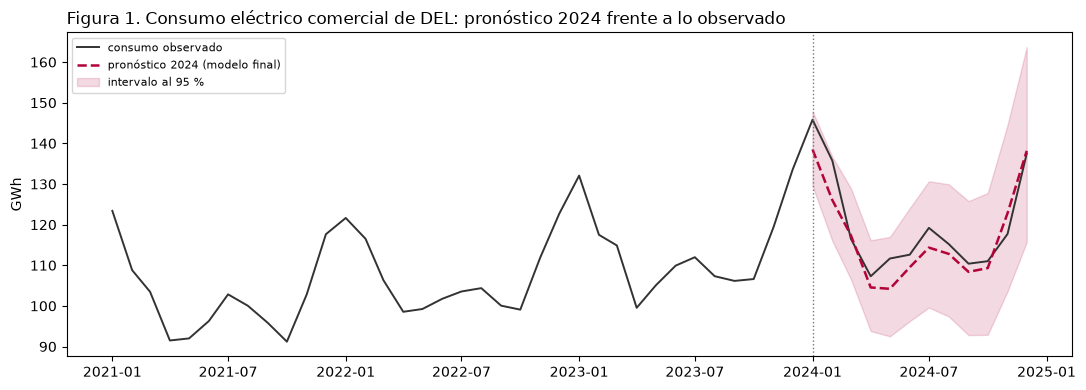

In [7]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(y["2021-01":"2024-12"].index, y["2021-01":"2024-12"], color="#333333", lw=1.4, label="consumo observado")
ax.plot(y["2024"].index, pred24, color="#b30338", lw=1.8, ls="--", label="pronóstico 2024 (modelo final)")
ax.fill_between(y["2024"].index, inf24, sup24, color="#b30338", alpha=0.15, label="intervalo al 95 %")
ax.axvline(pd.Timestamp("2024-01-01"), color="#777777", ls=":", lw=1)
ax.set_title("Figura 1. Consumo eléctrico comercial de DEL: pronóstico 2024 frente a lo observado", loc="left")
ax.set_ylabel("GWh"); ax.legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

<div style="border:2px dashed #b30338; border-left:8px solid #b30338; background:rgba(179,3,56,0.07); padding:10px 16px; border-radius:4px;">

### [BORRADOR] Lectura de la evaluación 2023 y 2024 (§1)

**En simple:** 2024 es el «examen final» que el modelo nunca vio. La vara es el naive estacional, que repite el mismo mes del año anterior.

| | Validación 2023 | Prueba 2024 |
|---|---|---|
| Modelo final: RMSE / MAE (GWh) | 6,85 / 6,40 | **4,87 / 4,00** |
| Naive: RMSE / MAE (GWh) | 7,26 / 6,53 | 8,19 / 6,67 |
| MASE modelo / naive | 0,98 / 1,00 | **0,61** / 1,02 |
| Meses dentro del IC 95 % | 12/12 | 12/12 |

**Ideas para mi texto:**
- **MASE < 1 = le gano al naive.** En 2023 le gano por poco (0,98); en 2024, por mucho (0,61): me equivoco ≈ 40 % menos.
- **Por qué el naive falla en 2024:** el consumo creció ≈ 5,6 % (media 2023: 113,66; 2024: 120,05 GWh) y el naive, al copiar 2023, se queda corto casi todos los meses.
- **El sesgo bajó:** en 2023 el modelo subestimó los 12 meses (+6,40 GWh); en 2024 subestima 9 de 12, con +2,89 GWh (2,4 % del consumo). Agregar 2023 al entrenamiento ayudó.
- **El intervalo funcionó:** 12 de 12 meses dentro en ambos años. Ojo: el 95 % no es una garantía; con 12 meses, 11 o 12 adentro es lo esperable. Es ancho (29,7 GWh, ≈ 25 % del nivel).
- **Figura 1** = la figura clave del informe (serie, pronóstico 2024 e intervalo).

_Borrador del asistente: ideas y cifras en lenguaje sencillo para **organizar** lo que voy a escribir. La guía de la S4 no permite que la IA redacte el informe: lo escribo yo en la celda [AUTOR] y declaro este apoyo. **Borrar esta celda antes de entregar.**_

</div>

**[AUTOR] Lectura de la evaluación 2023 y 2024**

> _Pendiente, con mis palabras. ¿Mi modelo supera al naive (MASE)? ¿Cuántos meses cayeron dentro del intervalo? ¿Persiste el sesgo de 2023?_

## 2. Tabla de modelos para el informe

In [8]:
# ==============================================================================
# Tabla de modelos para el informe (Formativa 4, criterio 2): modelo final, alternativas descartadas
# en las semanas 2 y 3, y naive estacional, en la validación 2023 y en la prueba 2024
# ==============================================================================
def pronostico_spec(orden, orden_est, fin_ent, ini, fin, arfima=False, garch=False):
    """Igual que ajustar_y_pronosticar, pero para cualquier especificación; d del ARFIMA se reestima con Hurst (R/S)."""
    lt = log_y[:fin_ent]
    h = len(log_y[ini:fin])
    m = SARIMAX(lt, exog=df[["covid"]][:fin_ent], order=orden, seasonal_order=orden_est).fit(disp=False)
    resid = m.resid.iloc[orden[1] + orden_est[1] * orden_est[3]:]
    p = m.get_forecast(h, exog=df[["covid"]].loc[ini:fin])
    media = p.predicted_mean.to_numpy()
    sd = ((p.conf_int(alpha=0.05).iloc[:, 1] - p.predicted_mean) / 1.96).to_numpy()
    d = np.nan
    if arfima:
        d = calcular_exponente_hurst(resid) - 0.5
        media = media + correccion_arfima(resid, d, h)
    if garch:
        sd = sd * estimar_garch11(resid, h)["escala_futura"]
    puntual = media + sd ** 2 / 2 if CORRECCION_SESGO else media
    return np.exp(puntual), np.exp(media - 1.96 * sd), np.exp(media + 1.96 * sd), d

MODELOS = {
    "B. SARIMA(0,1,1)(0,1,1)12 + covid (final)": dict(orden=(0, 1, 1), orden_est=(0, 1, 1, 12)),
    "A. SARIMA(0,1,0)(0,1,1)12 + covid (S2: descartado por Ljung-Box)": dict(orden=(0, 1, 0), orden_est=(0, 1, 1, 12)),
    "B + ARFIMA(0,d,0) (S3: sin memoria larga)": dict(orden=(0, 1, 1), orden_est=(0, 1, 1, 12), arfima=True),
    "B + bandas GARCH(1,1) (S3: sin volatilidad)": dict(orden=(0, 1, 1), orden_est=(0, 1, 1, 12), garch=True),
}
filas = []
for periodo, (fin_ent, ini, fin) in {"Validación 2023": ("2022-12", "2023-01", "2023-12"),
                                     "Prueba 2024": ("2023-12", "2024-01", "2024-12")}.items():
    real = y[ini:fin].to_numpy()
    y_ent = y[:fin_ent]
    escala = float((y_ent - y_ent.shift(12)).dropna().abs().mean())
    for nombre, spec in MODELOS.items():
        pred, inf, sup, d = pronostico_spec(fin_ent=fin_ent, ini=ini, fin=fin, **spec)
        m = metricas(real, pred)
        filas.append({"periodo": periodo, "modelo": nombre, **m, "MASE": m["MAE"] / escala,
                      **cobertura_y_ancho(real, inf, sup), "d (ARFIMA)": d})
    naive = y.shift(12)[ini:fin].to_numpy()
    m = metricas(real, naive)
    filas.append({"periodo": periodo, "modelo": "Naive estacional (referencia)", **m, "MASE": m["MAE"] / escala,
                  "Cobertura": np.nan, "Ancho medio": np.nan, "d (ARFIMA)": np.nan})
tabla_modelos = pd.DataFrame(filas).set_index(["periodo", "modelo"])
print("Tabla 2. Modelos en la validación 2023 y en la prueba 2024 (RMSE, MAE y ancho en GWh; MASE < 1 = mejor que el naive estacional)")
print(tabla_modelos.round(3).to_string())

Tabla 2. Modelos en la validación 2023 y en la prueba 2024 (RMSE, MAE y ancho en GWh; MASE < 1 = mejor que el naive estacional)
                                                                                   RMSE    MAE   MASE  Cobertura  Ancho medio  d (ARFIMA)
periodo         modelo                                                                                                                   
Validación 2023 B. SARIMA(0,1,1)(0,1,1)12 + covid (final)                         6.854  6.398  0.983        1.0       29.445         NaN
                A. SARIMA(0,1,0)(0,1,1)12 + covid (S2: descartado por Ljung-Box)  7.347  6.919  1.064        1.0       35.268         NaN
                B + ARFIMA(0,d,0) (S3: sin memoria larga)                         7.063  6.643  1.021        1.0       29.387       0.152
                B + bandas GARCH(1,1) (S3: sin volatilidad)                       6.855  6.399  0.984        1.0       29.328         NaN
                Naive estacional (referencia

<div style="border:2px dashed #b30338; border-left:8px solid #b30338; background:rgba(179,3,56,0.07); padding:10px 16px; border-radius:4px;">

### [BORRADOR] Tabla de modelos y por qué elegí el final (§2, criterio 2)

**En simple:** la Formativa 4 pide una tabla con el modelo final, lo que descarté en las semanas 2 y 3 y el naive, con métricas de 2023 y 2024. Es la **Tabla 2** de arriba.

| Modelo | RMSE 2023 | RMSE 2024 | MASE 2024 | Ancho IC 2024 | Por qué quedó fuera |
|---|---|---|---|---|---|
| **B (final)** | **6,85** | **4,87** | **0,61** | 29,7 | — |
| A (S2) | 7,35 | 4,88 | 0,62 | **38,5** | Ljung-Box en el rezago 24 (p = 0,019); su ventaja en el origen móvil no fue significativa (Diebold-Mariano p = 0,095) |
| B + ARFIMA (S3) | 7,06 | 4,89 | 0,62 | 29,7 | Sin memoria larga: H = 0,652 compatible con ruido blanco (37 % de 500 simulaciones lo supera) |
| B + GARCH (S3) | 6,85 | 4,87 | 0,62 | 29,5 | Sin volatilidad: ARCH-LM p = 0,639; α + β = 0,509 |
| Naive | 7,26 | 8,19 | 1,02 | — | Referencia mínima |

**Ideas para «por qué el modelo final» (una frase):**
- B tiene el menor error de 2023 (empatado con su versión con bandas GARCH, que usa el mismo pronóstico puntual) y en 2024 queda **empatado** con sus alternativas (diferencias de 0,03 GWh o menos). Con 12 meses, esas diferencias **no son sustantivas** (guía: interpretar con prudencia y mirar el MASE).
- Ante un empate, gana lo más simple y lo que pasó el diagnóstico: B tiene residuos sin autocorrelación y no agrega parámetros que la evidencia no respalda.
- A tiene un intervalo ≈ 30 % más ancho (38,5 frente a 29,7 GWh): para contratar energía, eso es más incertidumbre.

**Cadena de evidencia para el informe** (de mis hojas de decisiones): log y d = D = 1 (ADF −8,82 frente al crítico −2,90; KPSS 0,040 frente a 0,463) → 7 candidatos y selección de B (S2) → sin memoria larga ni volatilidad (S3) → prueba 2024 (S4).

_Borrador del asistente: ideas y cifras en lenguaje sencillo para **organizar** lo que voy a escribir. La guía de la S4 no permite que la IA redacte el informe: lo escribo yo en la celda [AUTOR] y declaro este apoyo. **Borrar esta celda antes de entregar.**_

</div>

**[AUTOR] Por qué elegí el modelo final**

> _Pendiente, con mis palabras. Una o dos frases con la cifra que lo respalda. ¿Qué evidencia de cada semana descarta cada alternativa?_

## 3. Del pronóstico al volumen a contratar

In [9]:
# ==============================================================================
# Del pronóstico al volumen a contratar (Formativa 4, criterio 3)
# Caso transversal, sección 3: contratar de menos obliga a comprar en el spot a 2-4 veces el precio contratado.
# Notebook de la Semana 2, §8: con costo de quedarse corto c_u y de sobrar c_o, el volumen óptimo es el
# cuantil q* = c_u / (c_u + c_o) de la distribución predictiva (cuantiles: exp(μ + z·σ), sin corrección).
# ==============================================================================
def cuantil(media_log, sd_log, q):
    return np.exp(media_log + stats.norm.ppf(q) * sd_log)

def pronostico_log(fin_ent, ini, fin):
    m = SARIMAX(log_y[:fin_ent], exog=df[["covid"]][:fin_ent], order=ORDEN, seasonal_order=ORDEN_ESTACIONAL).fit(disp=False)
    p = m.get_forecast(len(log_y[ini:fin]), exog=df[["covid"]].loc[ini:fin])
    return p.predicted_mean.to_numpy(), np.sqrt(np.asarray(p.var_pred_mean))

# (a) Prueba retrospectiva en 2024: ¿cuánto habría costado contratar cada volumen? (costo en GWh-equivalentes)
mu24, sd24 = pronostico_log("2023-12", "2024-01", "2024-12")
real24 = y["2024"].to_numpy()
filas_c = []
for k in (2, 3, 4):                                    # el spot cuesta k veces el contrato: c_u = k · c_o
    q = k / (k + 1)
    for etiqueta, vol in [("media corregida", np.exp(mu24 + sd24 ** 2 / 2)), (f"cuantil {q:.0%}", cuantil(mu24, sd24, q))]:
        corto = np.clip(real24 - vol, 0, None).sum()
        sobra = np.clip(vol - real24, 0, None).sum()
        filas_c.append({"c_u / c_o": k, "volumen": etiqueta, "contratado 2024 (GWh)": vol.sum(),
                        "faltó (GWh)": corto, "sobró (GWh)": sobra, "costo relativo": k * corto + sobra,
                        "meses cortos": int((real24 > vol).sum())})
tabla_costo = pd.DataFrame(filas_c).set_index(["c_u / c_o", "volumen"])
print(f"Tabla 3. Prueba retrospectiva 2024 (consumo real: {real24.sum():.1f} GWh). Costo relativo = c_u/c_o · faltante + sobrante")
print(tabla_costo.round(1).to_string())

# (b) Plan para los próximos 12 meses: una vez evaluado, el modelo se reestima con 2015-2024 (Semana 2, §8)
idx25 = pd.date_range("2025-01-01", periods=12, freq="MS")
m_full = SARIMAX(log_y, exog=df[["covid"]], order=ORDEN, seasonal_order=ORDEN_ESTACIONAL).fit(disp=False)
p25 = m_full.get_forecast(12, exog=pd.DataFrame({"covid": np.zeros(12)}, index=idx25))
mu25, sd25 = p25.predicted_mean.to_numpy(), np.sqrt(np.asarray(p25.var_pred_mean))
Q_STAR = 0.75                                          # c_u = 3 · c_o (valor central del rango 2-4 del caso)
plan = pd.DataFrame({"media corregida": np.exp(mu25 + sd25 ** 2 / 2),
                     "IC 95 % inferior": np.exp(mu25 - 1.96 * sd25), "IC 95 % superior": np.exp(mu25 + 1.96 * sd25),
                     "cuantil 67 %": cuantil(mu25, sd25, 2 / 3), "cuantil 75 % (a contratar)": cuantil(mu25, sd25, Q_STAR),
                     "cuantil 80 %": cuantil(mu25, sd25, 0.80)}, index=idx25.strftime("%Y-%m"))
print("\nTabla 4. Plan 2025 (GWh), modelo reestimado con 2015-2024")
print(plan.round(1).to_string())
print(f"Total 2025: media {plan['media corregida'].sum():.1f} GWh · cuantil 75 % {plan['cuantil 75 % (a contratar)'].sum():.1f} GWh "
      f"(+{100 * (plan['cuantil 75 % (a contratar)'].sum() / plan['media corregida'].sum() - 1):.1f} % sobre la media) · "
      f"coeficientes: ma.L1 = {m_full.params['ma.L1']:.3f}, ma.S.L12 = {m_full.params['ma.S.L12']:.3f}")

Tabla 3. Prueba retrospectiva 2024 (consumo real: 1440.6 GWh). Costo relativo = c_u/c_o · faltante + sobrante
                           contratado 2024 (GWh)  faltó (GWh)  sobró (GWh)  costo relativo  meses cortos
c_u / c_o volumen                                                                                       
2         media corregida                 1405.9         41.3          6.7            89.3             9
          cuantil 67%                     1442.4         20.1         22.0            62.3             6
3         media corregida                 1405.9         41.3          6.7           130.6             9
          cuantil 75%                     1465.4         13.8         38.6            79.8             3
4         media corregida                 1405.9         41.3          6.7           171.9             9
          cuantil 80%                     1481.4         10.9         51.7            95.5             3



Tabla 4. Plan 2025 (GWh), modelo reestimado con 2015-2024
         media corregida  IC 95 % inferior  IC 95 % superior  cuantil 67 %  cuantil 75 % (a contratar)  cuantil 80 %
2025-01            142.3             133.1             152.1         144.4                       145.6         146.4
2025-02            129.8             119.7             140.6         132.0                       133.4         134.3
2025-03            119.9             109.2             131.4         122.2                       123.6         124.6
2025-04            107.1              96.5             118.6         109.4                       110.9         111.8
2025-05            107.3              95.7             119.9         109.8                       111.3         112.4
2025-06            112.2              99.2             126.5         115.1                       116.8         118.0
2025-07            117.4             102.9             133.4         120.5                       122.5         123.8
2025-

<div style="border:2px dashed #b30338; border-left:8px solid #b30338; background:rgba(179,3,56,0.07); padding:10px 16px; border-radius:4px;">

### [BORRADOR] Del pronóstico al volumen a contratar (§3, criterio 3)

**En simple:** DEL no necesita solo un número. Necesita saber **cuánto contratar**. Quedarse corto obliga a comprar en el mercado spot a 2-4 veces el precio del contrato; sobrar cuesta lo que se pagó y no se usó. Por eso no conviene contratar la media, sino un **cuantil superior**: q* = c_u / (c_u + c_o) (Notebook S2, §8).

| Supuesto de costo (spot / contrato) | Cuantil a contratar |
|---|---|
| 2 veces | 67 % |
| **3 veces (valor central)** | **75 %** |
| 4 veces | 80 % |

**Prueba retrospectiva en 2024 (Tabla 3), con c_u = 3·c_o:**
- Contratar la **media**: faltaron 41,3 GWh en 9 de 12 meses → costo relativo 130,6.
- Contratar el **cuantil 75 %**: faltaron 13,8 GWh en solo 3 meses y sobraron 38,6 → costo relativo **79,8 (≈ 39 % menos)**.
- Con 2 o 4 veces la conclusión es la misma: el cuantil sale más barato que la media.

**Plan 2025 (Tabla 4; modelo reestimado con 2015-2024, recién después de evaluar):**
- Media: 1.440,7 GWh en el año. **Cuantil 75 %: 1.499,3 GWh (+4,1 %).**
- Los meses de mayor volumen son diciembre (148,8) y enero (145,6 GWh).

**Limitaciones para elegir (la guía pide al menos tres, con su efecto):**
- Solo 12 meses de prueba: el resultado de 2024 es una sola muestra.
- El costo 3 a 1 es un supuesto: si el spot cuesta 2 o 4 veces, cambia el cuantil (67 % a 80 %); lo debe validar el área comercial.
- Los residuos no eran normales (Jarque-Bera p = 0,001 en la S2, por el inicio del COVID): los cuantiles pueden quedar algo cortos en meses extremos.
- El MA estacional sigue casi en −1 (−0,970): la estacionalidad es casi fija; un cambio de patrón no se vería.
- El COVID es una sola indicadora y no se usan temperatura ni clientes.

_Borrador del asistente: ideas y cifras en lenguaje sencillo para **organizar** lo que voy a escribir. La guía de la S4 no permite que la IA redacte el informe: lo escribo yo en la celda [AUTOR] y declaro este apoyo. **Borrar esta celda antes de entregar.**_

</div>

**[AUTOR] Recomendación de volumen y limitaciones**

> _Pendiente, con mis palabras. ¿Recomiendo la media o un valor mayor? ¿Por qué? ¿Qué cifra lo respalda? Si una limitación fuera grave, ¿cambiaría el volumen o solo la confianza?_

## 4. Notas para el informe

- **Tabla:** lleve al informe `resumen`, reformateada como tabla del documento (no como salida de consola), junto con las cifras de validación de sus semanas 2 y 3.
- **Figura:** la figura anterior es la figura clave del informe.
- **MASE < 1** indica que el modelo supera al naive estacional; **MASE > 1**, que no lo supera. Interprete el resultado, sea cual sea.
- **Cobertura:** proporción de meses de la prueba que caen dentro del intervalo al 95 %.

<div style="border:2px dashed #b30338; border-left:8px solid #b30338; background:rgba(179,3,56,0.07); padding:10px 16px; border-radius:4px;">

### [BORRADOR] Esqueleto de la Formativa 4 (una página)

**En simple:** la Formativa 4 es un borrador de **una página** en PDF o DOCX (la tabla y la figura pueden ir en una segunda página), con tres bloques en el orden de la rúbrica. Nombre: `mcdi505_s4rmoncada`. Plazo según la guía: **viernes 23 de octubre**. Este notebook va como anexo.

| Bloque | Qué pide | Ideas y cifras para organizarlo |
|---|---|---|
| **1. Problema, metodología y solución** (5-8 líneas, sin jerga) | Qué decide la Gerencia, qué cuesta equivocarse en cada dirección y qué se propone + **figura clave** | Decisión: volumen mensual a contratar para el año siguiente. Quedarse corto: spot a 2-4 veces el precio; sobrar: energía pagada sin usar. Solución: un modelo que en 2024 se equivocó ≈ 4 GWh por mes (3,3 %) y ≈ 40 % menos que repetir el año anterior. Figura 1 |
| **2. Sustento técnico** | Tabla: modelo final, descartados de S2 y S3 y naive, con métricas 2023 y 2024, + una frase de por qué el final | Tabla 2 (§2). Frase: menor error en 2023, empatado en 2024 con alternativas más complejas o con intervalos más anchos, y el que pasó el diagnóstico de residuos en la S2 |
| **3. Recomendación y limitación** | Recomendación principal en 1-2 frases con su cifra + la limitación más importante | Contratar el cuantil 75 % (1.499,3 GWh en 2025, +4,1 % sobre la media); en 2024 habría bajado el costo ≈ 39 %. Limitación: supuesto de costo 3 a 1 o solo 12 meses de prueba |

**Antes de entregar (guía, bloque 4):** sin código en el informe; tablas como tablas del documento; figura numerada con leyenda; cada cifra rastreable a este notebook o a mis hojas; declaración de IA.

_Borrador del asistente: ideas y cifras en lenguaje sencillo para **organizar** lo que voy a escribir. La guía de la S4 no permite que la IA redacte el informe: lo escribo yo en la celda [AUTOR] y declaro este apoyo. **Borrar esta celda antes de entregar.**_

</div>

**[AUTOR] Borrador de la Formativa 4** _(lo escribo yo; aquí o directamente en el documento)_

**1. Problema, metodología y solución (5-8 líneas):**
> _Pendiente_

**2. Frase de por qué elegí el modelo final:**
> _Pendiente_

**3. Recomendación principal (con su cifra) y limitación más importante:**
> _Pendiente_

## Declaración de uso de asistentes de IA

**[AUTOR]** _(completar con lo que efectivamente hice)_

| Pregunta | Respuesta |
|---|---|
| ¿Utilizó asistentes de IA en esta entrega? | |
| ¿En qué partes específicas? | |
| ¿Qué verificó de forma independiente y cómo? | |

<div style="border:2px dashed #b30338; border-left:8px solid #b30338; background:rgba(179,3,56,0.07); padding:10px 16px; border-radius:4px;">

### [BORRADOR] Qué debería decir la declaración

- **Herramienta:** Claude (Anthropic), en Claude Code.
- **Qué hizo el asistente:** completó la plantilla con mi modelo de la S3 y agregó la corrección de sesgo, la tabla de modelos (2023 y 2024), la prueba retrospectiva de costos y el plan 2025; preparó estos borradores de ideas.
- **Qué hice yo:** las interpretaciones de las celdas [AUTOR], el borrador y el informe con mis palabras.
- **Cómo verifiqué:** ejecución completa con kernel reiniciado y cada cifra del informe contrastada con las tablas de este notebook y mis hojas de decisiones.

Ajustarlo a lo que efectivamente hice.

_Borrador del asistente: ideas y cifras en lenguaje sencillo para **organizar** lo que voy a escribir. La guía de la S4 no permite que la IA redacte el informe: lo escribo yo en la celda [AUTOR] y declaro este apoyo. **Borrar esta celda antes de entregar.**_

</div>